## Setup

### Imports

In [112]:
import pandas as pd
import matplotlib as plt
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

### Load and inspect

In [97]:
df = pd.read_csv('hair_health_dataset.csv')

print(df.head())
df.shape

  record_id  age  gender        ethnicity hair_type hair_texture hair_density  \
0   HH00001   21    Male         Hispanic     Curly       Medium       Medium   
1   HH00002   46  Female      Mixed_Other     Coily       Medium          Low   
2   HH00003   18    Male         Hispanic      Wavy       Coarse          Low   
3   HH00004   30    Male  African_Descent     Curly       Coarse       Medium   
4   HH00005   26  Female        Caucasian      Wavy       Medium       Medium   

  hair_fall_frequency hair_fall_level scalp_type  ... heat_styling_frequency  \
0               Daily            Mild     Normal  ...               Frequent   
1               Often            Mild        Dry  ...             Occasional   
2           Sometimes          Severe       Oily  ...             Occasional   
3           Sometimes        Moderate       Oily  ...               Frequent   
4              Rarely            Mild        Dry  ...                  Never   

  chemical_hair_treatment tight_

(2000, 38)

In [98]:
df.describe( 
    include='all'
)

,record_id,age,gender,ethnicity,hair_type,hair_texture,hair_density,hair_fall_frequency,hair_fall_level,scalp_type,...,heat_styling_frequency,chemical_hair_treatment,tight_hairstyle_frequency,environmental_exposure,recent_significant_weight_loss,family_history,treatment_history,age_of_onset_years,hair_health_score,hair_loss_class
count,2000,2000.000000,2000,2000,2000,2000,2000,2000,2000,2000,...,2000,2000,2000,2000,2000,2000,2000,1264.000000,2000.000000,2000
unique,2000,NaN,3,6,4,3,3,4,3,4,...,4,5,3,3,2,2,7,NaN,NaN,4
top,HH00001,NaN,Female,Asian,Straight,Medium,Medium,Sometimes,Mild,Oily,...,Occasional,No_Chemical_Treatment,Never,Moderate,No,No,No_Treatment,NaN,NaN,Mild
freq,1,NaN,968,526,760,834,938,729,905,604,...,671,897,889,921,1734,1185,1024,NaN,NaN,928
mean,NaN,34.632000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.920886,69.173250,NaN
std,NaN,12.228792,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,12.084163,14.695988,NaN
min,NaN,15.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,14.000000,12.800000,NaN
25%,NaN,25.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,22.000000,59.675000,NaN
50%,NaN,34.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.000000,69.900000,NaN
75%,NaN,43.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,39.000000,79.700000,NaN


## Data cleaning

### Missing values

In [99]:
missing_values = df.isnull().sum()

# only show columns with missing values
data_gap = missing_values.to_frame(name="missing count")
data_gap["missing percent"] = missing_values[missing_values > 0] / df.shape[0] 

data_gap[data_gap["missing percent"] > 0]



,missing count,missing percent
age_of_onset_years,736,0.368


In [100]:
df[["age_of_onset_years", "hair_loss_class"]]


,age_of_onset_years,hair_loss_class
0,14.0,Mild
1,NaN,No_Hair_Loss
2,14.0,Moderate
3,27.0,Moderate
4,NaN,No_Hair_Loss
...,...,...
1995,NaN,No_Hair_Loss
1996,64.0,Mild
1997,32.0,Moderate
1998,NaN,No_Hair_Loss


`age_of_onset_years` is the age when hair loss started. It is null when `hair_loss_class` is `No_Hair_Loss`.

### Category values

Check the unique values of the columns for any abnormalities.

In [101]:
text_cols = df.select_dtypes(exclude="number").columns.drop("record_id")

for col in text_cols:
    print(col, df[col].unique())

gender ['Male' 'Female' 'Other']
ethnicity ['Hispanic' 'Mixed_Other' 'African_Descent' 'Caucasian' 'Middle_Eastern'
 'Asian']
hair_type ['Curly' 'Coily' 'Wavy' 'Straight']
hair_texture ['Medium' 'Coarse' 'Fine']
hair_density ['Medium' 'Low' 'High']
hair_fall_frequency ['Daily' 'Often' 'Sometimes' 'Rarely']
hair_fall_level ['Mild' 'Severe' 'Moderate']
scalp_type ['Normal' 'Dry' 'Oily' 'Combination']
scalp_oiliness ['High' 'Low' 'Medium']
scalp_dryness ['Medium' 'High' 'Low']
scalp_itching ['Mild' 'Severe' 'No_Itching' 'Moderate']
dandruff_presence ['No' 'Yes']
stress_level ['Medium' 'Low' 'High']
diet_type ['Non_Vegetarian' 'Vegetarian' 'Eggetarian' 'Vegan']
smoking_status ['Never' 'Current' 'Former']
alcohol_consumption ['Non_Drinker' 'Occasional' 'Regular']
nutritional_deficiency ['No_Deficiency' 'Biotin' 'Multiple' 'Iron' 'Vitamin_D' 'Omega_3'
 'Protein']
medical_condition ['No_Condition' 'Thyroid_Disorder' 'Alopecia_Areata' 'PCOS'
 'Other_Autoimmune' 'Iron_Deficiency_Anemia']
life_s

## Encoding

### One-hot encoding

Categories with no real order, where one value cannot be quantified as greater than another.

In [102]:
# non ordinal columns [to be one hot encoded]
non_ordinal_cols = ["gender", "ethnicity", "hair_type", "scalp_type", "dandruff_presence", "diet_type", "smoking_status","nutritional_deficiency", "medical_condition",  "life_stage_hormonal_event", "medication_affecting_hair", "chemical_hair_treatment", "recent_significant_weight_loss", "family_history", "treatment_history" ]

# one hot encode
encoded_df = pd.get_dummies(df, columns=non_ordinal_cols)

encoded_df.head()


,record_id,age,hair_texture,hair_density,hair_fall_frequency,hair_fall_level,scalp_oiliness,scalp_dryness,scalp_itching,wash_frequency_per_week,...,recent_significant_weight_loss_Yes,family_history_No,family_history_Yes,treatment_history_Ayurvedic_Home_Remedies,treatment_history_Finasteride,treatment_history_Hair_Transplant,treatment_history_Minoxidil,treatment_history_No_Treatment,treatment_history_Other,treatment_history_PRP_Therapy
0,HH00001,21,Medium,Medium,Daily,Mild,High,Medium,Mild,8,...,True,True,False,False,True,False,False,False,False,False
1,HH00002,46,Medium,Low,Often,Mild,Low,High,Severe,3,...,False,True,False,False,False,False,True,False,False,False
2,HH00003,18,Coarse,Low,Sometimes,Severe,Low,Low,No_Itching,3,...,False,False,True,False,False,False,False,False,True,False
3,HH00004,30,Coarse,Medium,Sometimes,Moderate,High,Low,Severe,1,...,False,False,True,False,False,False,False,True,False,False
4,HH00005,26,Medium,Medium,Rarely,Mild,Low,High,No_Itching,6,...,False,False,True,False,False,False,False,False,False,True


### Ordinal encoding

Asked AI to write this block because it was repetitive.

In [103]:
ordered = {
    "hair_texture": {"Fine": 0, "Medium": 1, "Coarse": 2},
    "hair_density": {"Low": 0, "Medium": 1, "High": 2},
    "hair_fall_frequency": {"Rarely": 0, "Sometimes": 1, "Often": 2, "Daily": 3},
    "hair_fall_level": {"Mild": 0, "Moderate": 1, "Severe": 2},
    "scalp_oiliness": {"Low": 0, "Medium": 1, "High": 2},
    "scalp_dryness": {"Low": 0, "Medium": 1, "High": 2},
    "scalp_itching": {"No_Itching": 0, "Mild": 1, "Moderate": 2, "Severe": 3},
    "stress_level": {"Low": 0, "Medium": 1, "High": 2},
    "alcohol_consumption": {"Non_Drinker": 0, "Occasional": 1, "Regular": 2},
    "heat_styling_frequency": {"Never": 0, "Occasional": 1, "Frequent": 2, "Daily": 3},
    "tight_hairstyle_frequency": {"Never": 0, "Occasional": 1, "Frequent": 2},
    "environmental_exposure": {"Low": 0, "Moderate": 1, "High": 2},
    "hair_loss_class": {"No_Hair_Loss": 0, "Mild": 1, "Moderate": 2, "Severe": 3},
}

encoded_df = encoded_df.replace(ordered)

/var/folders/lv/v4jqssxs0n371bxjhgzrry480000gn/T/ipykernel_76644/827646133.py:17: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  encoded_df = encoded_df.replace(ordered)


## Exploratory analysis

### Correlation with the target

Top 10 positive and negative correlations with `hair_loss_class`.

In [130]:
hair_loss_class_corr = encoded_df.corr(numeric_only=True)["hair_loss_class"].sort_values(ascending=False)

print("top 11")
print(hair_loss_class_corr.head(11), "\n")

print("bottom 11")
print(hair_loss_class_corr.tail(11), "\n")

print("top 15 absolute values")
print(hair_loss_class_corr.abs().sort_values(ascending=False).head(15), "\n")

top 11
hair_loss_class                               1.000000
family_history_Yes                            0.462172
medical_condition_Alopecia_Areata             0.248825
age                                           0.240288
medication_affecting_hair_Yes_Chemotherapy    0.202799
recent_significant_weight_loss_Yes            0.165175
smoking_status_Current                        0.143205
stress_level                                  0.141258
heat_styling_frequency                        0.120416
treatment_history_No_Treatment                0.114711
life_stage_hormonal_event_Menopause           0.109356
Name: hair_loss_class, dtype: float64 

bottom 11
sleep_hours                                     -0.094040
treatment_history_Minoxidil                     -0.106486
dandruff_presence_No                            -0.109100
protein_frequency_per_week                      -0.119427
chemical_hair_treatment_No_Chemical_Treatment   -0.121502
smoking_status_Never                            

### Columns removed

Drop `hair_health_score` because it is a regressive result tied to the classification and can reveal the target, as noted by its high correlation and in the data dictionary.

Also drop `age_of_onset_years` because it is a perfect mapping of the no hair loss class. The rows stay: dropping them would remove the entire no hair loss class and 36% of the data.

In [105]:
encoded_df.drop(columns=["hair_health_score", "record_id", "age_of_onset_years"], inplace=True)

### Relationships with the target

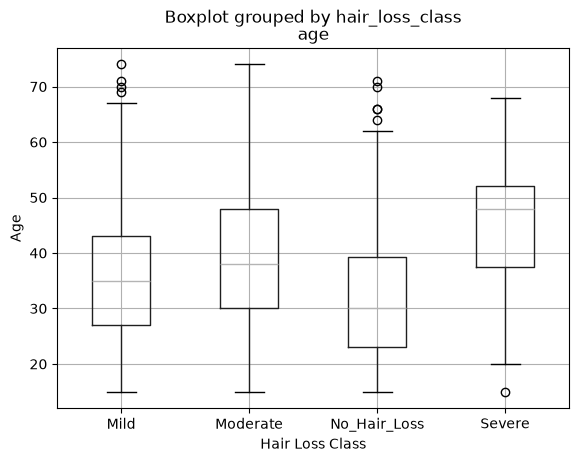

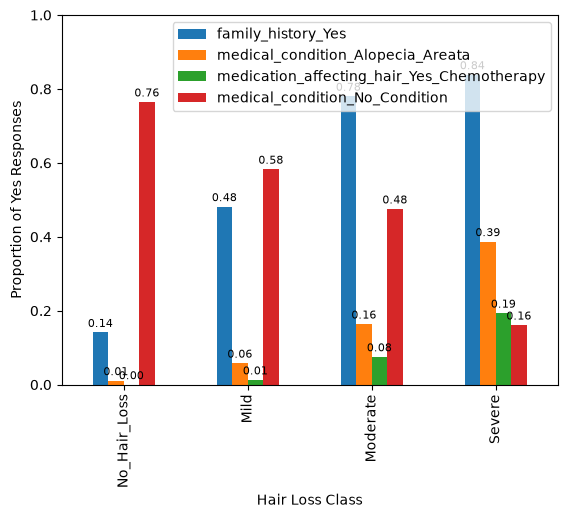

In [141]:
labels = {0: "No_Hair_Loss", 1: "Mild", 2: "Moderate", 3: "Severe"}

encoded_df.assign(hair_loss_class=encoded_df["hair_loss_class"].map(labels)).boxplot(
    column="age", by="hair_loss_class", xlabel="Hair Loss Class", ylabel="Age"
)

binary = [
    "family_history_Yes",
    "medical_condition_Alopecia_Areata",
    "medication_affecting_hair_Yes_Chemotherapy",
    "medical_condition_No_Condition"
]
rates = encoded_df.groupby("hair_loss_class")[binary].mean()
rates.index = rates.index.map(labels)
ax = rates.plot(kind="bar", xlabel="Hair Loss Class", ylabel="Proportion of Yes Responses", ylim=(0, 1))
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=2, fontsize=8)


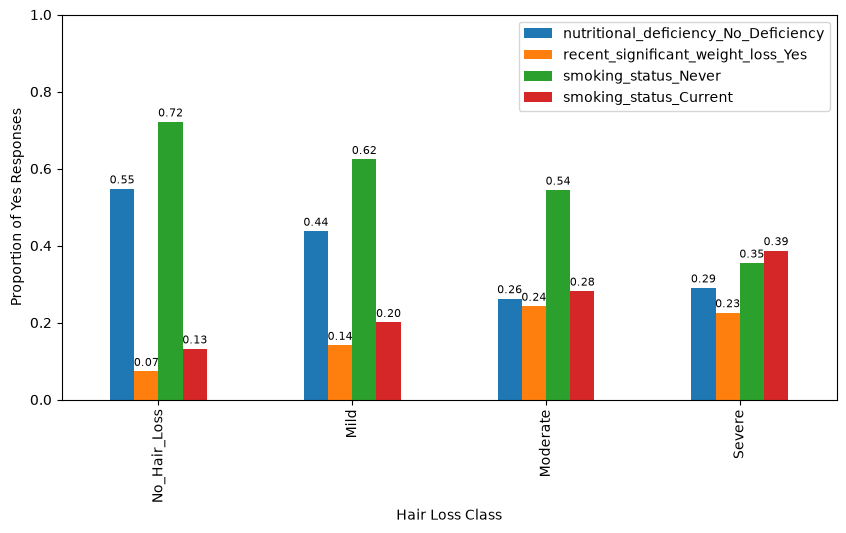

In [140]:

binary = [
    "nutritional_deficiency_No_Deficiency",
    "recent_significant_weight_loss_Yes",
    "smoking_status_Never",
    "smoking_status_Current"
]
rates = encoded_df.groupby("hair_loss_class")[binary].mean()
rates.index = rates.index.map(labels)
ax = rates.plot(
    kind="bar",
    xlabel="Hair Loss Class",
    ylabel="Proportion of Yes Responses",
    ylim=(0, 1),
    figsize=(10, 5),
)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=2, fontsize=8)



### Features to keep

Suggestion is to use `family_history_Yes`, `medical_condition_Alopecia_Areata`, `medical_condition_No_Condition`, `age`, and `smoking_status_Never`.

### Class balance

In [108]:
df["hair_loss_class"].value_counts()

hair_loss_class
Mild            928
No_Hair_Loss    736
Moderate        305
Severe           31
Name: count, dtype: int64

### Train-test split and SMOTE

In [113]:
# Use Stratification and SMOTE to balance the data
train_df, test_df = train_test_split(encoded_df, test_size=0.2, random_state=42, stratify=encoded_df["hair_loss_class"])

smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(train_df.drop(columns=["hair_loss_class"]), train_df["hair_loss_class"])

# Check the proportions of the target class after balancing
y_res.value_counts()

hair_loss_class
1    742
0    742
3    742
2    742
Name: count, dtype: int64